# Fair-lending disparity testing: selection rates, the four-fifths rule, parity, equalized odds and calibration within groups

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 05 of this topic
- **Reading time:** about 55 minutes

## Objectives

By the end of this notebook you can:

- compute the selection (approval) rate of each group from decisions, and from them the parity difference, the adverse impact ratio and the four-fifths flag, on exact counts;
- test a rate gap with the two-proportion z test and Fisher's exact test, and say why a very small p-value on a very large sample does not measure how large the disparity is;
- state the legal frame honestly: the four-fifths rule is an employment benchmark used by analogy, Regulation B as amended in 2026 says the effects test does not apply under the ECOA, the Fair Housing Act is a separate statute, and gross HMDA rate disparities are indicators only;
- compute the outcome-based metrics (equal opportunity, equalized odds, calibration and AUC within groups) on planted data, and see why they cannot run on HMDA, which has no outcome;
- read the committed HMDA comparison of Delaware 2018 and 2019 (case C21) and the committed Taiwan fairness battery (case C20), and rebuild their rows with the engine.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the packages and print their versions
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.fairness import inference, metrics, plants
from riskvalidation.fairness.metrics import SelectionRate
from riskvalidation.validation import fairness as vf

ROOT = Path("../../..").resolve()
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

- **The engine's planted-bias generators** (`riskvalidation.fairness.plants`): a logistic portfolio with a binary protected group, a decision and an outcome, and one planted bias at a time with the truth known exactly. `ThresholdBiasPlant` approves the protected group at a lower cut-off by a `gap` in log-odds; `LabelNoiseBiasPlant` flips a share of the protected group's observed outcomes although the model treats both groups alike. Synthetic, from a seed, no licence class.
- **The committed HMDA comparison of Delaware, 2018 to 2019** (`data/derived/C21/pair-2018-19.json`; owner: this repository). HMDA is the Home Mortgage Disclosure Act data published by the FFIEC and the CFPB (class mirror-allowed; the licence sentence of the data is UNVERIFIED, so the document says so). It holds the number of applications and approvals per group for race, ethnicity, sex and age (loans originated or approved, action taken 1 and 2, against denied, 3), the tests the pipeline ran and a block of legal statements. **HMDA has no outcome** (no default, no repayment) and withholds the credit score, so only the selection-rate tests can run on it.
- **The committed Taiwan fairness battery of case C20** (`data/derived/C20/perturbation-grid.json`; derived from the UCI Taiwan credit-card data, CC BY 4.0): twelve engine rows, four tests by three attributes (sex, marital status and age band) on the model's PD at a fixed cut-off. The first cell opens both documents.

In [2]:
# Open both committed documents and print the engine that baked each one
hmda = json.loads((ROOT / "data" / "derived" / "C21" / "pair-2018-19.json").read_text(encoding="utf-8"))
taiwan = json.loads((ROOT / "data" / "derived" / "C20" / "perturbation-grid.json").read_text(encoding="utf-8"))
for label, doc in (("C21 pair-2018-19", hmda), ("C20 perturbation-grid", taiwan)):
    print(f'{label:22s} baked with riskvalidation {doc["provenance"]["riskvalidation_version"]} | test rows {len(doc["tests"])}')
print("rows used to fit and to confirm:", hmda["outputs"]["scope"]["rows_fit"], hmda["outputs"]["scope"]["rows_confirm"], "|", hmda["outputs"]["scope"]["state"])
print("legal label of the document:", hmda["outputs"]["legal"]["label"]["en"])

C21 pair-2018-19       baked with riskvalidation 0.8.1 | test rows 87
C20 perturbation-grid  baked with riskvalidation 0.8.1 | test rows 16
rows used to fit and to confirm: 36515 41834 | DE
legal label of the document: no legal claim


## Method

### Step 1: selection rates

For a favourable decision $d_i \in \{0, 1\}$ (here: approved) and a group label $g_i$, the selection rate of group $g$ is $r_g = x_g / n_g$, with $x_g$ the favourable count and $n_g$ the size. The engine works on the **counts**, in exact integer arithmetic, and rounds once when it produces a float. The committed document stores the counts per group, so the next cell rebuilds a decision vector and a group vector with exactly those counts (this is the aggregate, not the 31,000 individual applications) and calls the engine's `group_selection_rates`. The rates must equal the committed ones.

In [3]:
# Rebuild decisions and groups from the committed counts of the race attribute and compute the selection rates with the engine
def arrays_of(attribute):
    decision = np.concatenate([np.repeat([1, 0], [g["n_approved"], g["n_denied"]]) for g in attribute["groups"]])
    group = np.concatenate([np.repeat(g["group"], g["n"]) for g in attribute["groups"]])
    return decision, group


race = hmda["outputs"]["attributes"][0]
decision, group = arrays_of(race)
rates = metrics.group_selection_rates(decision, group)
print(race["field"], "| reference group:", race["reference_group"], "| rows:", len(decision))
for g in race["groups"]:
    r = rates[g["group"]]
    print(f'{g["group"]:44s} n {r.n:6d} approved {r.favourable:6d} rate {r.rate:.4f} | same as committed {r.rate == g["selection_rate"]}')

derived_race | reference group: White | rows: 31342
American Indian or Alaska Native             n    139 approved     71 rate 0.5108 | same as committed True
Asian                                        n   1359 approved   1037 rate 0.7631 | same as committed True
Black or African American                    n   5370 approved   3315 rate 0.6173 | same as committed True
Native Hawaiian or Other Pacific Islander    n     86 approved     50 rate 0.5814 | same as committed True
White                                        n  24293 approved  18839 rate 0.7755 | same as committed True
2 or more minority races                     n     95 approved     47 rate 0.4947 | same as committed True


### Step 2: parity, the adverse impact ratio and the four-fifths rule

With a reference group $h$ (the dossier's choice for race is the largest group, White):

$$\text{parity difference: } r_g - r_h, \qquad \text{adverse impact ratio: } \mathrm{AIR}_g = \frac{r_g}{r_h}.$$

The **demographic parity** test reports the largest absolute difference against the reference and is green up to a tolerance of 0.05 (a convention), amber above, never red. The four-fifths rule of the US employment guidelines (29 CFR 1607.4(D)) compares each group with the **highest-rate** group $t$ (not necessarily the reference) and flags a group whose rate is less than four fifths of it:

$$\text{flag}_g \iff 5\,x_g\,n_t < 4\,x_t\,n_g .$$

Both rules are decided on the integers, never on a float that could miss the boundary by one unit in the last place: 60 of 100 against 75 of 100 has a float ratio of $0.7999999999999999$ and an exact ratio of $4/5$, which is **not** flagged. **The four-fifths rule is an employment benchmark used by analogy; it is not a credit-law threshold**, and the engine's result says so in a field of its own. The next cell shows the boundary, then computes the parity differences, the ratios and the flags for the race groups.

In [4]:
# The boundary case 60/100 against 75/100, then parity differences, ratios and four-fifths flags of the race groups
edge = metrics.group_selection_rates(np.r_[np.ones(60), np.zeros(40), np.ones(75), np.zeros(25)].astype(int), np.r_[np.repeat("A", 100), np.repeat("B", 100)])
print("60/100 against 75/100 | float ratio", (60 / 100) / (75 / 100), "| flagged by the engine", metrics.four_fifths_flag(edge).flag["A"])
reference = race["reference_group"]
parity = metrics.demographic_parity_difference(rates, reference)
air = metrics.adverse_impact_ratio(rates, reference)
four_fifths = metrics.four_fifths_flag(rates)
print("highest-rate group:", four_fifths.highest_rate_group, "| benchmark label:", four_fifths.label, "| is a credit-law threshold:", four_fifths.is_credit_law_threshold)
for g in race["groups"]:
    name = g["group"]
    print(f"{name:44s} difference {parity[name]:+.4f} | AIR {air[name]:.4f} | flag {four_fifths.flag[name]}")

60/100 against 75/100 | float ratio 0.7999999999999999 | flagged by the engine False
highest-rate group: White | benchmark label: employment benchmark | is a credit-law threshold: False
American Indian or Alaska Native             difference -0.2647 | AIR 0.6587 | flag True
Asian                                        difference -0.0124 | AIR 0.9840 | flag False
Black or African American                    difference -0.1582 | AIR 0.7960 | flag True
Native Hawaiian or Other Pacific Islander    difference -0.1941 | AIR 0.7497 | flag True
White                                        difference +0.0000 | AIR 1.0000 | flag False
2 or more minority races                     difference -0.2808 | AIR 0.6380 | flag True


The engine's tests wrap these functions into `TestResult` rows with a light. The next cell rebuilds the rates of all four attributes of the document (race, ethnicity, sex and age), calls the engine's `demographic_parity` and `adverse_impact` tests and compares the metric and the light with the committed row.

In [5]:
# For each attribute rebuild the rates from the committed counts, call the two engine tests and compare with the committed rows
committed = {(t["test_id"], t["segment"]): t for t in hmda["tests"]}
print(f'{"attribute":20s} {"groups":>7s} {"parity gap":>11s} {"light":>6s} {"AIR min":>8s} {"light":>6s} same as committed')
for attribute in hmda["outputs"]["attributes"]:
    dec, grp = arrays_of(attribute)
    r = metrics.group_selection_rates(dec, grp)
    dp = vf.demographic_parity("hmda", r, attribute["reference_group"])
    ai = vf.adverse_impact("hmda", r, attribute["reference_group"])
    old_dp, old_ai = committed[("fair.demographic_parity", attribute["field"])], committed[("fair.adverse_impact", attribute["field"])]
    same = abs(dp.metric - old_dp["metric"]) < 1e-12 and dp.light.value == old_dp["light"] and abs(ai.metric - old_ai["metric"]) < 1e-12 and ai.light.value == old_ai["light"]
    print(f'{attribute["field"]:20s} {len(r):7d} {dp.metric:11.4f} {dp.light.value:>6s} {ai.metric:8.4f} {ai.light.value:>6s} {same}')

attribute             groups  parity gap  light  AIR min  light same as committed
derived_race               6      0.2808  amber   0.6380  amber True
derived_ethnicity          2      0.0881  amber   0.8829  green True
derived_sex                2      0.0019  green   0.9974  green True
applicant_age              7      0.0933  amber   0.8082  green True


### Step 3: is a gap more than chance? The z test and Fisher's exact test

A difference of rates can be tested. For group 1 with $x_1$ of $n_1$ and group 2 with $x_2$ of $n_2$, the pooled two-proportion z statistic and its two-sided p-value are

$$z = \frac{x_1/n_1 - x_2/n_2}{\sqrt{\hat{p}(1-\hat{p})\,(1/n_1 + 1/n_2)}}, \quad \hat{p} = \frac{x_1 + x_2}{n_1 + n_2}, \qquad p = 2\bigl(1 - \Phi(|z|)\bigr),$$

and Fisher's exact test uses the hypergeometric law on the $2 \times 2$ table (the engine reports the sample odds ratio). The light is red below 0.01, amber below 0.05. A p-value answers "is the gap compatible with chance?", **not** "is the gap large": with 24,293 applications in the reference group a gap of a few points is far from chance. The next cell tests every group against the reference, rebuilds the committed rows and compares.

In [6]:
# Test every race group against the reference with the z test and Fisher's test and compare with the committed rows
ref = rates[reference]
print(f'{"group":44s} {"z":>8s} {"p z":>9s} {"p Fisher":>9s} {"odds ratio":>14s} light same')
for g in race["groups"]:
    if g["group"] == reference:
        continue
    s = rates[g["group"]]
    z = inference.two_proportion_z_test(s.favourable, s.n, ref.favourable, ref.n)
    f = inference.fisher_exact_test(s.favourable, s.n, ref.favourable, ref.n)
    row = vf.two_proportion_z("hmda", s.favourable, s.n, ref.favourable, ref.n)
    old = committed[("fair.two_proportion_z", f'derived_race|{g["group"]} vs {reference}')]
    print(f'{g["group"]:44s} {z.statistic:8.3f} {z.p_value:9.2e} {f.p_value:9.2e} {f.odds_ratio:14.4f} {row.light.value:5s} {abs(row.statistic - old["statistic"]) < 1e-9 and row.light.value == old["light"]}')

group                                               z       p z  p Fisher     odds ratio light same
American Indian or Alaska Native               -7.440  1.01e-13  1.21e-11         0.3023 red   True
Asian                                          -1.068  2.86e-01  2.86e-01         0.9324 green True
Black or African American                     -24.124 1.40e-128 3.00e-120         0.4670 red   True
Native Hawaiian or Other Pacific Islander      -4.302  1.70e-05  7.36e-05         0.4021 red   True
2 or more minority races                       -6.534  6.40e-11  3.03e-09         0.2835 red   True


### Step 4: the legal frame, as the committed document states it

The document carries the legal statements the pipeline read from primary sources, so that no number in it is read as more than it is. The next cell prints them: the label of the whole document, the sentence of Regulation B as amended on 2026-04-22 (12 CFR 1002.6(a), 91 FR 21668), the statement of the Interagency Procedures about gross HMDA disparities, and the flags that say the unconditional rates are indicators only and the controlled disparity an approximation of comparative evidence. The notebook does not interpret them beyond what they say.

In [7]:
# Print the legal statements the document carries, in the language of this notebook where it has two
legal = hmda["outputs"]["legal"]
print("label:", legal["label"]["en"])
print("Regulation B:", legal["regulation_b"]["citation"])
print("  verbatim quote, in English:", legal["regulation_b"]["quote"])
print("Interagency procedures:", legal["procedures"]["citation"])
print("  verbatim quote, in English:", legal["procedures"]["quote"])
print("unconditional rates are:", legal["unconditional_rates_are"], "| controlled disparity is:", legal["controlled_disparity_is"], "| a finding of violation:", legal["is_a_finding_of_violation"])
print("licence of the data:", hmda["outputs"]["licence"]["status"])

label: no legal claim
Regulation B: 12 CFR 1002.6(a), as amended at 91 FR 21668 (2026-04-22, effective 2026-07-21)
  verbatim quote, in English: The Act does not provide that the 'effects test' applies for determining whether there is discrimination in violation of the Act.
Interagency procedures: Interagency Fair Lending Examination Procedures, August 2009, appendix, printed page 26
  verbatim quote, in English: Gross HMDA denial or approval rate disparities are not appropriate for disproportionate adverse impact analysis because they typically cannot be attributed to a specific policy or criterion.
unconditional rates are: indicators-only | controlled disparity is: approximation-of-comparative-evidence | a finding of violation: False
licence of the data: UNVERIFIED


### Step 5: the outcome-based metrics, on planted bias

With an outcome $y$ (here 1 = repaid), a decision $d$ (1 = approved) and a group, the metrics of Hardt, Price and Srebro (2016) compare error rates:

$$\mathrm{TPR}_g = P(d=1 \mid y=1, g), \qquad \mathrm{FPR}_g = P(d=1 \mid y=0, g),$$

$$\text{equal opportunity gap} = \max_g \mathrm{TPR}_g - \min_g \mathrm{TPR}_g, \qquad \text{equalized odds gap} = \max\bigl(\text{TPR gap},\; \text{FPR gap}\bigr).$$

Calibration within groups is the expected calibration error of the PD within each group, and the AUC by group is the AUC of the score within each group. All four need an outcome: on a dataset that declares none, like HMDA, the engine refuses with a message. The next cell shows the refusal on the HMDA decisions, then the metrics on three plants: no bias, a threshold bias (the protected group is approved at a cut-off lower by 0.8 in log-odds) and a label-noise bias (the model treats the groups alike but 20% of the protected group's observed outcomes are flipped).

In [8]:
# The refusal on HMDA, then equal opportunity, equalized odds, calibration and AUC by group on three planted datasets
try:
    metrics.equalized_odds_difference(None, decision, group)
except ValueError as error:
    print("refused:", type(error).__name__, "| the engine names the missing outcome:", "outcome: none" in str(error))
draws = {}
specs = (("no bias", plants.ThresholdBiasPlant(n=20000, gap=0.0, seed=1)),
         ("threshold bias", plants.ThresholdBiasPlant(n=20000, gap=0.8, seed=1)),
         ("label-noise bias", plants.LabelNoiseBiasPlant(n=20000, noise=0.2, seed=1)))
for label, plant in specs:
    d = plant.draw_default()
    draws[label] = d
    pd_model = np.clip(d["pd"], 1e-6, 1 - 1e-6)
    eo = metrics.equal_opportunity_difference(d["y"], d["decision"], d["group"])
    eq = metrics.equalized_odds_difference(d["y"], d["decision"], d["group"])
    cal = metrics.calibration_within_groups(pd_model, d["defaults"], d["group"])
    auc = metrics.auc_by_group(pd_model, d["defaults"], d["group"])
    rate = metrics.group_selection_rates(d["decision"], d["group"])
    print(f'{label:26s} selection rates {rate["0"].rate:.3f} / {rate["1"].rate:.3f} | equal opportunity {eo:.4f} | equalized odds {eq:.4f}')
    print(f'{"":26s} ECE by group {cal["0"]:.4f} / {cal["1"]:.4f} | AUC by group {auc["0"]:.4f} / {auc["1"]:.4f}')

refused: ValueError | the engine names the missing outcome: True
no bias                    selection rates 0.704 / 0.702 | equal opportunity 0.0019 | equalized odds 0.0157
                           ECE by group 0.0093 / 0.0132 | AUC by group 0.7671 / 0.7740
threshold bias             selection rates 0.704 / 0.446 | equal opportunity 0.2518 | equalized odds 0.2775
                           ECE by group 0.0093 / 0.0132 | AUC by group 0.7671 / 0.7740
label-noise bias           selection rates 0.704 / 0.702 | equal opportunity 0.0389 | equalized odds 0.1229
                           ECE by group 0.0093 / 0.0977 | AUC by group 0.7671 / 0.6458


### Step 6: the committed Taiwan battery

The Taiwan model of case C20 was screened for the same four outcome-based metrics across sex, marital status and age band. The twelve rows are labelled in the document as "labelled fairness evidence", with no four-fifths flag and no group-rate test. The next cell prints them with the light each gets from the engine's cut points (0.05 amber, 0.10 red, conventions), and rebuilds one of them from the committed group rates.

In [9]:
# Print the twelve committed rows of the Taiwan battery and rebuild one equalized-odds value from the group rates
battery = taiwan["outputs"]["fairness_battery"]
print("label:", battery["label"], "| model:", battery["model"], "| rows:", len(battery["rows"]))
for r in battery["rows"]:
    print(f'{r["test_id"]:32s} {r["attribute"]:10s} value {r["value"]:.4f} groups {len(r["groups"])} light {r["light"]}')
row = next(t for t in taiwan["tests"] if t["test_id"] == "fair.equalized_odds" and t["segment"] == "sex")
rates_by_group = row["extras"]["rates_by_group"]
tpr_gap = max(g["tpr"] for g in rates_by_group.values()) - min(g["tpr"] for g in rates_by_group.values())
fpr_gap = max(g["fpr"] for g in rates_by_group.values()) - min(g["fpr"] for g in rates_by_group.values())
print("fair.equalized_odds / sex | committed", round(row["metric"], 6), "| max(TPR, FPR) gaps from the group rates", round(max(tpr_gap, fpr_gap), 6))

label: labelled-fairness-battery | model: uci-taiwan | rows: 12
fair.equalized_odds              sex        value 0.0431 groups 2 light green
fair.equalized_odds              age        value 0.1083 groups 4 light red
fair.equalized_odds              marital_status value 0.1127 groups 3 light red
fair.equal_opportunity           sex        value 0.0149 groups 2 light green
fair.equal_opportunity           age        value 0.1003 groups 4 light red
fair.equal_opportunity           marital_status value 0.0325 groups 3 light green
fair.calibration_within_groups   sex        value 0.0877 groups 2 light amber
fair.calibration_within_groups   age        value 0.1047 groups 4 light red
fair.calibration_within_groups   marital_status value 0.1565 groups 3 light red
fair.auc_by_group                sex        value 0.0120 groups 2 light green
fair.auc_by_group                age        value 0.0211 groups 4 light green
fair.auc_by_group                marital_status value 0.0568 groups 3 light 

### Step 7: the evidence, drawn

Left: the selection rate of each race group of Delaware 2018 against the reference rate, with the four-fifths line (80% of the highest rate). Right: the equalized-odds gap of the three plants.

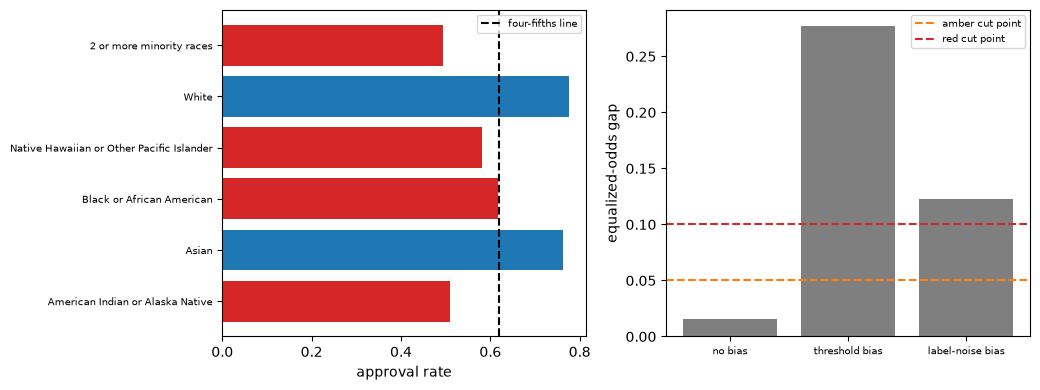

In [10]:
# Left: race-group selection rates with the four-fifths line; right: equalized-odds gap of the three plants
fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 4.0))
names = [g["group"] for g in race["groups"]]
left.barh(names, [rates[n].rate for n in names], color=["tab:red" if four_fifths.flag[n] else "tab:blue" for n in names])
left.axvline(0.8 * rates[four_fifths.highest_rate_group].rate, color="black", linestyle="--", label="four-fifths line")
left.set_xlabel("approval rate")
left.tick_params(axis="y", labelsize=7)
left.legend(fontsize=7)
gaps = [metrics.equalized_odds_difference(d["y"], d["decision"], d["group"]) for d in draws.values()]
right.bar(range(3), gaps, color="tab:gray")
right.set_xticks(range(3))
right.set_xticklabels(list(draws), fontsize=7)
right.axhline(0.05, color="tab:orange", linestyle="--", label="amber cut point")
right.axhline(0.10, color="tab:red", linestyle="--", label="red cut point")
right.set_ylabel("equalized-odds gap")
right.legend(fontsize=7)
fig.tight_layout()
plt.show()

## Results

- **The counts reproduce the committed rates exactly.** The race groups of Delaware 2018 have approval rates from 0.5108 (American Indian or Alaska Native, 139 applications) to 0.7755 (White, 24,293 applications), and every rate rebuilt by the engine equals the committed one. All four attributes (race, ethnicity, sex and age) give the same metric and the same light as the committed rows.
- **The parity gap and the four-fifths flag answer different questions.** For race the largest gap against the White group is 0.2808 (amber, a convention of 0.05) and four of the five other groups are flagged against the highest-rate group: the Black group has a ratio of 0.7960, below 0.8 by a hair, the American Indian group 0.6587. The Asian group (0.9840) is not flagged and its z test is compatible with chance (z = -1.068, p = 0.286). For ethnicity the gap is 0.0881 (amber) with a ratio of 0.8829 (green); for age the gap is 0.0933 (amber) and the lowest ratio 0.8082 (green); for sex the gap is 0.0019 (green).
- **A p-value is not a size.** The z test of the Black against the White group gives z = -24.124 and p = 1.40e-128, and the American Indian group z = -7.440 with p = 1.01e-13, from 139 applications. Both are red. The odds ratios (0.4670 and 0.3023) say how large, which the p-value does not. Fisher's exact p-values agree in sign and order of magnitude. The engine reproduces the lights of all committed rows.
- **The legal frame bounds what the rates mean.** The document is labelled "no legal claim". It carries the sentence of Regulation B as amended (12 CFR 1002.6(a)) that the Act does not provide that the effects test applies, the Interagency Procedures sentence that gross HMDA rate disparities are not appropriate for disproportionate adverse impact analysis, and the flags that the unconditional rates are indicators only and a finding of violation is false. The four-fifths result carries `is_credit_law_threshold = False`, and the licence of the HMDA data is UNVERIFIED. None of the tests in this notebook decides discrimination.
- **The outcome-based metrics need an outcome and find what was planted.** The engine refuses to compute them on HMDA. On the plants: without bias the equal-opportunity gap is 0.0019 and the equalized-odds gap 0.0157; with the threshold bias the selection rates are 0.704 and 0.446 and the gaps 0.2518 and 0.2775. With label noise the selection rates are the same (0.704 and 0.702) because the model treats both groups alike, yet the equalized-odds gap is 0.1229, the protected group's calibration error is 0.0977 against 0.0093 and its AUC 0.6458 against 0.7671: the observed outcome, not the model, is what is wrong. A validator who finds those gaps has to ask first whether the outcome is measured alike in both groups.
- **The committed Taiwan battery gives a mixed picture.** Of the twelve rows, the equalized odds and equal opportunity gaps by age (0.1083 and 0.1003) and the equalized odds gap by marital status (0.1127) are red, the calibration within groups is red by age (0.1047) and marital status (0.1565) and amber by sex (0.0877), and the AUC by group is green for sex and age and amber for marital status (0.0568). The rows are labelled evidence with no four-fifths flag; the equalized odds value of sex is rebuilt from the group rates (0.043078) and equals the committed one. All rows were baked with riskvalidation 0.8.1.

What the results do not show: no test here establishes a cause, and gross rates of approval mix every difference between the groups' applications; the engine's lights are conventions (0.05 and 0.10, 5% and 1%) and the four-fifths rule is not a credit-law threshold; the plants are synthetic; and the Taiwan model is a research model, not a lender's.

## Summary

- Selection rates are computed on exact counts; parity, the adverse impact ratio and the four-fifths flag are decided on the integers, and the four-fifths rule is an employment benchmark used by analogy, never a credit-law threshold.
- A two-proportion z test and Fisher's exact test say whether a gap is compatible with chance; on thousands of applications they reject for small gaps, so the size of the gap and the odds ratio are read beside them.
- The committed HMDA comparison of Delaware 2018 is reproduced by the engine from its counts for race, ethnicity, sex and age; it is labelled "no legal claim", its rates are indicators only, and the licence of the data is UNVERIFIED.
- The outcome-based metrics (equal opportunity, equalized odds, calibration and AUC by group) need an outcome and refuse to run without one; a label-noise bias shows that a gap in them can come from the outcome and not from the model.
- The committed Taiwan battery has red rows by age and marital status, and every row is labelled evidence, not a finding of violation.

**What to try next.** Notebook 07 asks what remains of a disparity after the permitted controls, whether it repeats the next year, and what a situation test finds.

## References

- Hardt, M., Price, E. and Srebro, N. (2016), Equality of opportunity in supervised learning, arXiv 1610.02413. https://arxiv.org/abs/1610.02413
- 29 CFR 1607.4(D), Uniform Guidelines on Employee Selection Procedures: the four-fifths rule, an employment benchmark. https://www.law.cornell.edu/cfr/text/29/1607.4
- CFPB (2026), Equal Credit Opportunity Act (Regulation B), final rule, 91 FR 21620, effective 2026-07-21. https://www.govinfo.gov/content/pkg/FR-2026-04-22/pdf/2026-07804.pdf
- OCC, FDIC, Federal Reserve Board, OTS and NCUA (2009), Interagency Fair Lending Examination Procedures. https://www.federalreserve.gov/boarddocs/caletters/2009/0906/09-06_attachment.pdf
- Kozodoi, N., Jacob, J. and Lessmann, S. (2022), Fairness in credit scoring: assessment, implementation and profit implications, European Journal of Operational Research 297(3). https://doi.org/10.1016/j.ejor.2021.06.023
- FFIEC and CFPB, Home Mortgage Disclosure Act data publication (the licence sentence of the data is UNVERIFIED). https://ffiec.cfpb.gov/data-publication/
- Yeh, I-C. and Lien, C-H., Default of credit card clients, UCI Machine Learning Repository (CC BY 4.0), the Taiwan cards of the C20 variants. https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients